# ML Project : Appliances Energy Prediction

the objective : Predict energy consumed by households appliances in Wh, logged every 10 minutes.

# Part A : Dataset Preparation & Cleaning

**Importing libraries**

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              ConfusionMatrixDisplay, classification_report)
df_raw = pd.read_csv("KAG_energydata_complete.csv")
df = df_raw.copy()

In [2]:
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)
print("Environment ready.")

Environment ready.


In [3]:
print(df.shape)
print("Number of observations : ", df.shape[0])
print("Number of variables : ", df.shape[1])

(19735, 29)
Number of observations :  19735
Number of variables :  29


In [4]:
df.head()
df.describe()

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
count,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000,19735.000000
mean,97.694958,3.801875,21.686571,40.259739,20.341219,40.420420,22.267611,39.242500,20.855335,39.026904,19.592106,50.949283,7.910939,54.609083,20.267106,35.388200,22.029107,42.936165,19.485828,41.552401,7.411665,755.522602,79.750418,4.039752,38.330834,3.760707,24.988033,24.988033
std,102.524891,7.935988,1.606066,3.979299,2.192974,4.069813,2.006111,3.254576,2.042884,4.341321,1.844623,9.022034,6.090347,31.149806,2.109993,5.114208,1.956162,5.224361,2.014712,4.151497,5.317409,7.399441,14.901088,2.451221,11.794719,4.194648,14.496634,14.496634
min,10.000000,0.000000,16.790000,27.023333,16.100000,20.463333,17.200000,28.766667,15.100000,27.660000,15.330000,29.815000,-6.065000,1.000000,15.390000,23.200000,16.306667,29.600000,14.890000,29.166667,-5.000000,729.300000,24.000000,0.000000,1.000000,-6.600000,0.005322,0.005322
25%,50.000000,0.000000,20.760000,37.333333,18.790000,37.900000,20.790000,36.900000,19.530000,35.530000,18.277500,45.400000,3.626667,30.025000,18.700000,31.500000,20.790000,39.066667,18.000000,38.500000,3.666667,750.933333,70.333333,2.000000,29.000000,0.900000,12.497889,12.497889
50%,60.000000,0.000000,21.600000,39.656667,20.000000,40.500000,22.100000,38.530000,20.666667,38.400000,19.390000,49.090000,7.300000,55.290000,20.033333,34.863333,22.100000,42.375000,19.390000,40.900000,6.916667,756.100000,83.666667,3.666667,40.000000,3.433333,24.897653,24.897653
75%,100.000000,0.000000,22.600000,43.066667,21.500000,43.260000,23.290000,41.760000,22.100000,42.156667,20.619643,53.663333,11.256000,83.226667,21.600000,39.000000,23.390000,46.536000,20.600000,44.338095,10.408333,760.933333,91.666667,5.500000,40.000000,6.566667,37.583769,37.583769
max,1080.000000,70.000000,26.260000,63.360000,29.856667,56.026667,29.236000,50.163333,26.200000,51.090000,25.795000,96.321667,28.290000,99.900000,26.000000,51.400000,27.230000,58.780000,24.500000,53.326667,26.100000,772.300000,100.000000,14.000000,66.000000,15.500000,49.996530,49.996530


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9  

Redundant Data Removal: Identify missing values and remove duplicate rows or highly correlated, identical features. Duplicate entries artificiality skew your evaluation metrics if they leak across splits.

In [6]:
# No Missing values
print("\n Missing data:\n",df.isnull().sum())


 Missing data:
 date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64


In [7]:
# No duplicates
print("Number of duplicate records : ",(df.duplicated().sum()))
print("  duplicate timestamps :", df["date"].duplicated().sum())
print("  monotonically increasing:", df["date"].is_monotonic_increasing)

Number of duplicate records :  0
  duplicate timestamps : 0
  monotonically increasing: True


The file is clean : No missing values, no duplicates timestamps,
75% of observations are null in "Lights" but we will not remove the variable, it may contribute to explain the target variable.

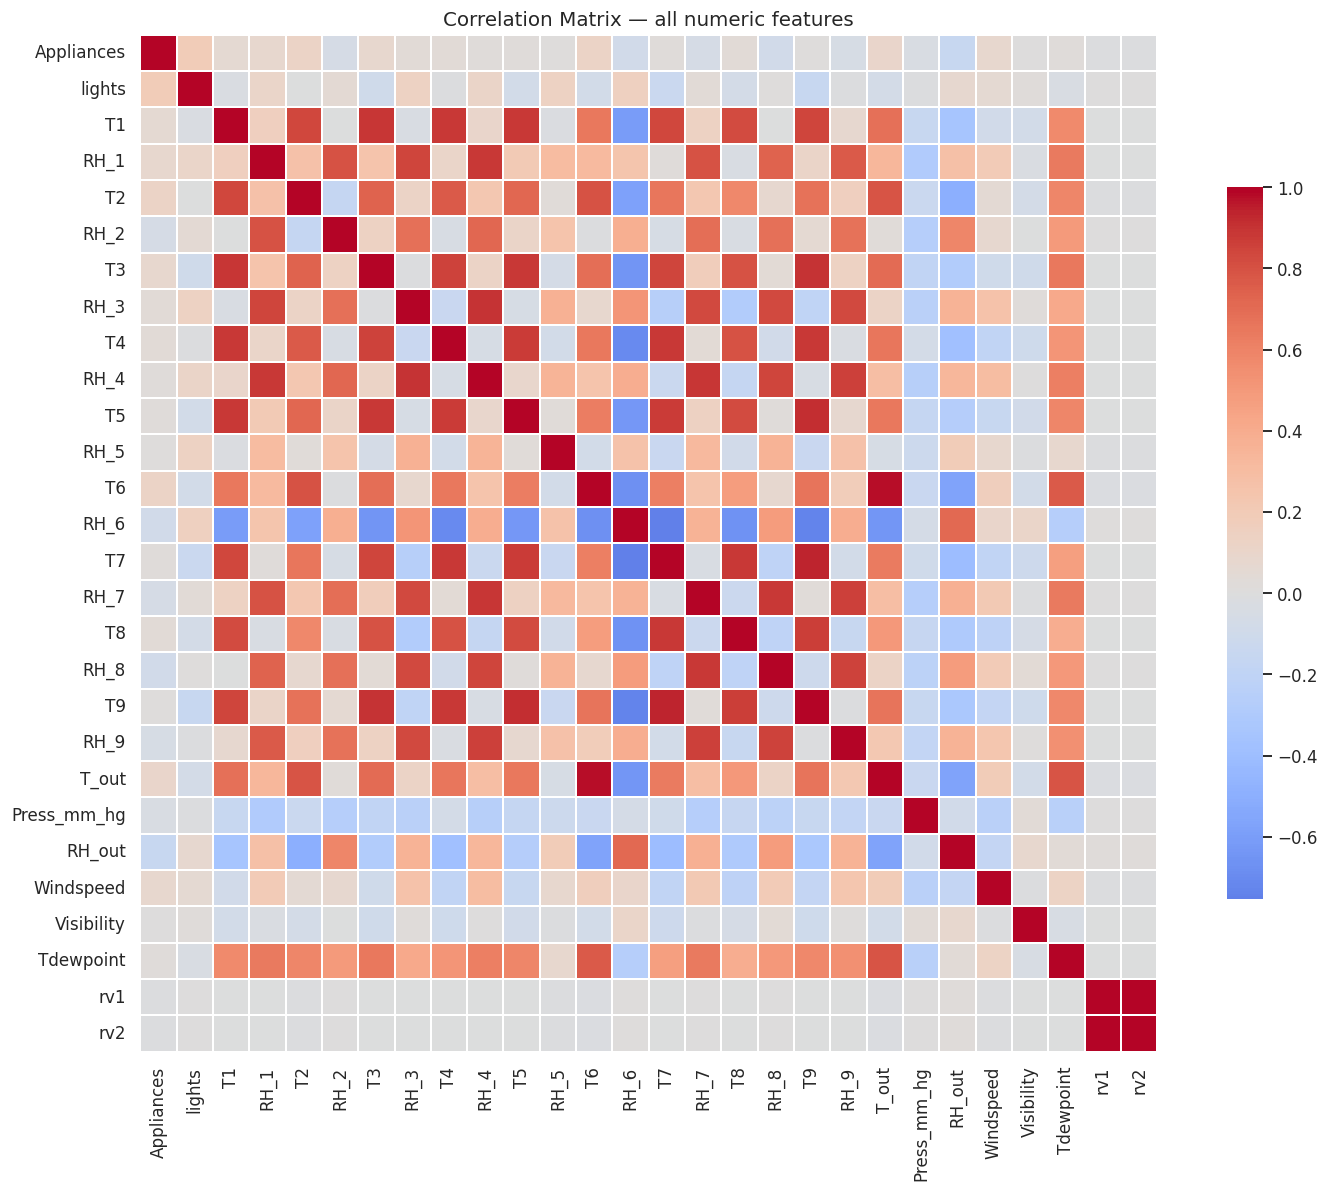

In [8]:
# Redundant features: correlation matrix
num = df.drop(columns=["date"])
corr = num.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
            linewidths=.3, cbar_kws={"shrink": .7})
plt.title("Correlation Matrix — all numeric features", fontsize=13)
plt.tight_layout(); plt.show()

In [9]:
# List every feature pair above the redundancy threshold.
THRESH = 0.9
c = corr.abs()
pairs = (c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
          .stack()
          .sort_values(ascending=False))
redundant = pairs[pairs >= THRESH]

print(f"Feature pairs with |r| >= {THRESH}:\n")
print(redundant.to_string())

Feature pairs with |r| >= 0.9:

rv1  rv2      1.000000
T6   T_out    0.974787
T7   T9       0.944776
T5   T9       0.911055
T3   T9       0.901324


T9: Parent's room temperature correlates with T3,T5,T7. it is the most redundant node and adds no independent information. we remove `T9`.   
rv1 and rv2 random variables : identical, we keep `rv1`.                         
T6 (Temperature outside the building (north side)) correlates 0.975 with T_out (Temperature outside (from Chievres weather station)- northeast of Brussels). We keep `T_out`

In [10]:
DROP_REDUNDANT = ["rv2", "T9", "T6"]
df= df.drop(columns = DROP_REDUNDANT)
print("Dropped:", DROP_REDUNDANT)
print("Shape after removing the variables:", df.shape)

Dropped: ['rv2', 'T9', 'T6']
Shape after removing the variables: (19735, 26)


In [11]:
print(df.columns.tolist())

['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1']


In [12]:
# IQR rule on "Appliances" to identify outliers
y = df["Appliances"]
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
lo = q1 - 1.5 * iqr
hi = q3 + 1.5 * iqr
iqr_out = ((y < lo) | (y > hi))

In [13]:
print(f"IQR fence           : [{lo:.1f}, {hi:.1f}] Wh")
print(f"Flagged by IQR      : {iqr_out.sum():5d}  ({100*iqr_out.mean():.2f}% of data)")

IQR fence           : [-25.0, 175.0] Wh
Flagged by IQR      :  2138  (10.83% of data)


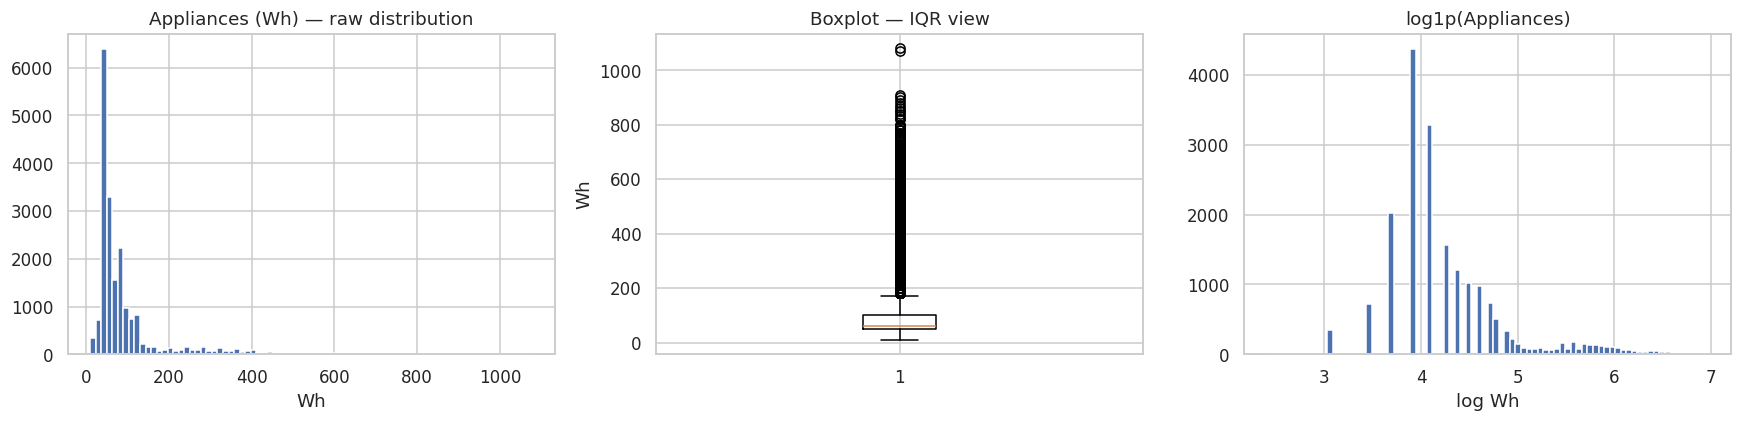

count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

Skewness raw      : 3.386
Skewness log1p    : 1.190


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(y, bins=80)
axes[0].set_title("Appliances (Wh) — raw distribution"); axes[0].set_xlabel("Wh")
axes[1].boxplot(y); axes[1].set_title("Boxplot — IQR view"); axes[1].set_ylabel("Wh")
axes[2].hist(np.log1p(y), bins=80)
axes[2].set_title("log1p(Appliances)"); axes[2].set_xlabel("log Wh")
plt.tight_layout(); plt.show()

print(y.describe())
print(f"\nSkewness raw      : {y.skew():.3f}")
print(f"Skewness log1p    : {np.log1p(y).skew():.3f}")

In [ ]:

# 2,138 records (10.8% of the dataset) as outliers. Deleting them would be methodological error:

# 1.They are the signal, not the noise.The flagged records carry a large share of total
# energy consumption and cluster tightly in the 17:00–21:00 evening band — exactly when someone
#    comes home and runs appliances. an "outlier" that repeats on a daily schedule is a
#    pattern, not an error.

# 2.Deleting them doesnt solve the problem.The point of this model is to anticipate peak load.
# A model trained only on 10–175 Wh baseline data would predict the flat standby
#  consumption perfectly and be useless for demand-response or load-shifting decisions.


Outlier detection performed on appliances to identify unusually high or low energy-consumption observations. However, statistical outliers (10,83% of data )were not removed because extreme energy-consumption values may represent a particular household energy-use events rather than measurement errors. Therefore, observations were retained unless there was evidence that they were erroneous.

In [202]:

# The timestamp : driver of household energy use (human routine).
# We expand timestamp into calendar features, and encode the cyclical ones with sine/cosine pairs
# so that 23:00 and 00:00 sit next to each other in feature space instead of at opposite ends of a 0–23 line.
# `NSM` (number of seconds since midnight) is the feature used in the original paper on this
# dataset and is included for the same reason.


df["date"] = pd.to_datetime(df["date"], errors="coerce")
d = df["date"]
df["hour"]       = d.dt.hour
df["minute"]     = d.dt.minute
df["dayofweek"]  = d.dt.dayofweek
df["month"]      = d.dt.month
df["day"]        = d.dt.day
df["week"]       = d.dt.isocalendar().week.astype(int)
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)

# seconds since midnight
df["NSM"]  = d.dt.hour * 3600 + d.dt.minute * 60

# Cyclical encodings
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["dow_sin"]  = np.sin(2 * np.pi * df["dayofweek"] / 7)
df["dow_cos"]  = np.cos(2 * np.pi * df["dayofweek"] / 7)

print("Engineered features added. Final shape:", df.shape)
df[["date", "hour", "NSM", "is_weekend", "hour_sin", "hour_cos", "Appliances"]].head()



Engineered features added. Final shape: (19735, 38)


,date,hour,NSM,is_weekend,hour_sin,hour_cos,Appliances
0,2016-01-11 17:00:00,17,61200,0,-0.965926,-0.258819,60
1,2016-01-11 17:10:00,17,61800,0,-0.965926,-0.258819,60
2,2016-01-11 17:20:00,17,62400,0,-0.965926,-0.258819,50
3,2016-01-11 17:30:00,17,63000,0,-0.965926,-0.258819,50
4,2016-01-11 17:40:00,17,63600,0,-0.965926,-0.258819,60


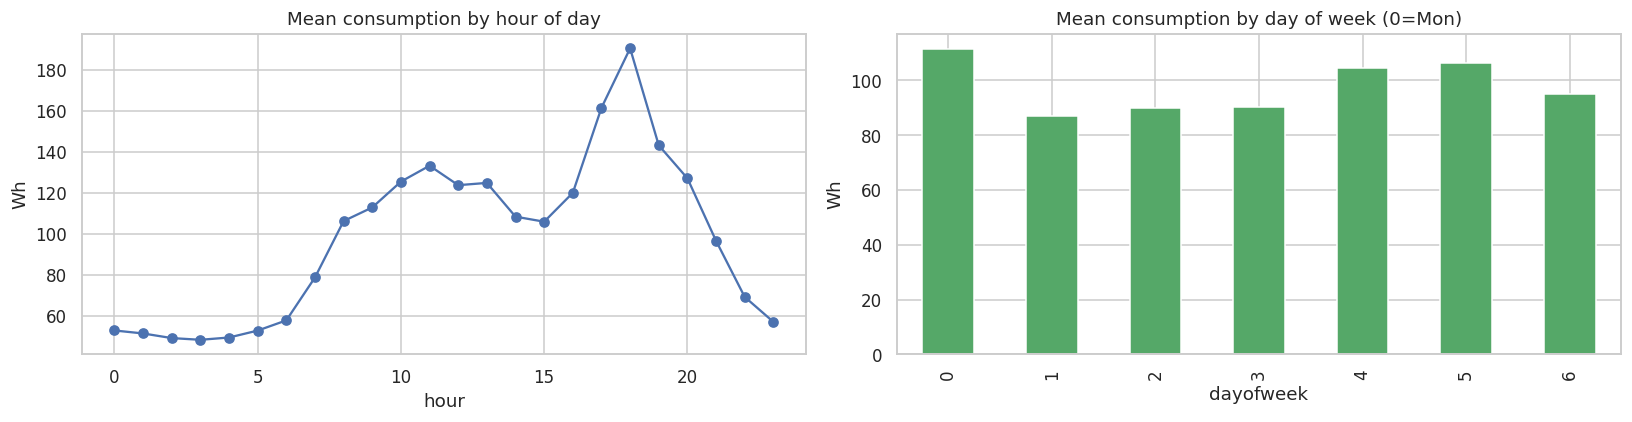

In [208]:
# Feature check: does the engineered time feature help explain the target?
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
df.groupby("hour")["Appliances"].mean().plot(marker="o", ax=axes[0], color="#4c72b0")
axes[0].set_title("Mean consumption by hour of day"); axes[0].set_ylabel("Wh")
df.groupby("dayofweek")["Appliances"].mean().plot(kind="bar", ax=axes[1], color="#55a868")
axes[1].set_title("Mean consumption by day of week (0=Mon)"); axes[1].set_ylabel("Wh")
plt.tight_layout(); plt.show()


I decide to make it a classification problem instead so we wont lose information about almost 11% outliers. for that, Build the 3 class target from Appliances:


*   Low    : <= 50 Wh   (Baseline)
*   Medium : 51-100 Wh  (Normal activity)
*   High   : > 100 Wh   (Big appliance is running)

In [25]:
# Build the 3-class target from Appliances
df["Load_Class"] = pd.cut(df["Appliances"], bins=[-1, 50, 100, 10000],
                           labels=["Low", "Medium", "High"])
print(df["Load_Class"].value_counts())

# Final X / y  (drop date and the original Appliances column )
TARGET = "Load_Class"
X = df.drop(columns=["date","Appliances", TARGET])
y = df[TARGET].astype(str)


X = df.drop(columns=["date", "Appliances", "Load_Class"])
y = df["Load_Class"].astype(str)
feature_names = list(X.columns)
print(f"Target: {TARGET}")
print("\nFeatures:", feature_names)

Load_Class
Medium    8040
Low       7462
High      4233
Name: count, dtype: int64
Target: Load_Class

Features: ['lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2', 'hour', 'dayofweek', 'is_weekend']


# PART B : Data Splitting & Cross Validation

In [28]:
# 80/20 split and we will Keep the same class proportions in both testing and training dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training set : {len(X_train):>6,} rows ({len(X_train)/len(X):.0%})")
print(f"Test set     : {len(X_test):>6,} rows ({len(X_test)/len(X):.0%})   << SEALED\n")


Training set : 15,788 rows (80%)
Test set     :  3,947 rows (20%)   << SEALED



In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# PART C : Algorithm Training

the target we want to predict is categirical , data are labeled --> Classification (SL)

In [32]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(probability=True, random_state=42),
}

# Scale features once (needed for LogReg, KNN, SVM)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("\n--- Baseline cross-validation (accuracy) ---")
for name, model in models.items():
    scores = cross_val_score(model, X_train_s, y_train, cv=cv, scoring="f1_macro")
    print(f"{name:22s} F1-macro = {scores.mean():.3f}")



--- Baseline cross-validation (accuracy) ---
Logistic Regression    F1-macro = 0.567
Naive Bayes            F1-macro = 0.499
KNN                    F1-macro = 0.657
Decision Tree          F1-macro = 0.678
Random Forest          F1-macro = 0.735
SVM                    F1-macro = 0.642


# PART D : Hyperparameter Tuning & Model Evaluation

Define the hyperparameter values to test for each model. GridSearchCV will try all possible combinations of these values using cross-validation and select the combination that gives the highest F1-score. The chosen parameters are then used to build the best version of each model.

In [35]:
# GridSearchCV identifies the best hyperparameter combination for each model based on cross-validation.
# while the Test F1 shows its performance on the unseen test set.

param_grids = {
    "Logistic Regression": {"C": [0.1, 1, 10]},
    "Naive Bayes": {"var_smoothing": [1e-9, 1e-7]},
    "KNN": {"n_neighbors": [5, 15, 25]},
    "Decision Tree": {"max_depth": [5, 10, None]},
    "Random Forest": {"n_estimators": [100], "max_depth": [10, None]},
    "SVM": {"C": [1, 10], "gamma": ["scale"]},
}

best_models = {}
results = []

for name, model in models.items():
    grid = GridSearchCV(model, param_grids[name], cv=cv, scoring="f1_macro", n_jobs=-1)
    grid.fit(X_train_s, y_train)
    best_models[name] = grid.best_estimator_

    # Final evaluation on the sealed test set
    pred = grid.predict(X_test_s)
    proba = grid.predict_proba(X_test_s)

    results.append({
        "Model": name,
        "Best Params": grid.best_params_,
        "CV F1-macro": grid.best_score_,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Precision": precision_score(y_test, pred, average="macro"),
        "Test Recall": recall_score(y_test, pred, average="macro"),
        "Test F1": f1_score(y_test, pred, average="macro"),
        "Test ROC-AUC": roc_auc_score(y_test, proba, multi_class="ovr"),
    })
    print(f"{name:22s} best={grid.best_params_}  test F1={results[-1]['Test F1']:.3f}")

Logistic Regression    best={'C': 0.1}  test F1=0.557
Naive Bayes            best={'var_smoothing': 1e-09}  test F1=0.512
KNN                    best={'n_neighbors': 5}  test F1=0.653
Decision Tree          best={'max_depth': None}  test F1=0.692
Random Forest          best={'max_depth': None, 'n_estimators': 100}  test F1=0.749
SVM                    best={'C': 10, 'gamma': 'scale'}  test F1=0.692


 The Random Forest achieves the highest test F1-score (0.749) among the evaluated models. Decision Tree and SVM obtain the same performance (0.692), followed by KNN (0.653). Logistic Regression (0.557) and Naive Bayes (0.512) show lower performance.
Overall, the results suggest that tree-based and non-linear models are better suited to capture the relationships between the features and the target classes in this dataset than the simpler linear or probabilistic approaches tested here.

**Interprétation modèle par modèle**

Logistic Regression — F1 = 0.557

Le modèle obtient une performance modérée. Le meilleur paramètre est C=0.1, ce qui indique que, parmi les valeurs testées, une régularisation plus forte donne les meilleurs résultats sur la validation croisée. La relation entre les variables et les classes peut donc être suffisamment complexe pour qu'un modèle linéaire soit limité.

Naive Bayes — F1 = 0.512

C'est le score le plus faible. Le modèle semble moins bien adapté aux relations présentes dans les données. Le meilleur var_smoothing est la plus petite valeur testée (1e-9), ce qui signifie que l'ajout de smoothing plus important n'a pas amélioré la performance.

KNN — F1 = 0.653

KNN améliore nettement les performances par rapport aux deux modèles précédents. Le meilleur résultat est obtenu avec seulement 5 voisins, ce qui suggère que les observations proches les unes des autres contiennent une information utile pour déterminer la classe.

Decision Tree — F1 = 0.692

Le modèle obtient une bonne performance avec max_depth=None, c'est-à-dire sans limitation explicite de la profondeur de l'arbre. Cela suggère que des règles de décision relativement complexes permettent de mieux séparer les classes.

Random Forest — F1 = 0.749

C'est le F1 le plus élevé sur le jeu de test parmi les modèles évalués. Le Random Forest utilise 100 arbres et aucune limite de profondeur. Sa meilleure performance peut s'expliquer par sa capacité à capturer des relations non linéaires et des interactions entre variables, tout en combinant plusieurs arbres plutôt qu'un seul.

SVM — F1 = 0.692

Le SVM obtient le même F1 que le Decision Tree. Le meilleur C=10 correspond, parmi les valeurs testées, à une régularisation moins forte. gamma="scale" permet à l'algorithme de déterminer automatiquement une valeur adaptée à l'échelle des données.

# PART E : Performance Comparaison

In [38]:
# Convert the list of model results into a DataFrame and use the model names as the index.
# The models are then sorted from highest to lowest
# Test F1-score to make comparison easier.

results_df = pd.DataFrame(results).set_index("Model").sort_values("Test F1", ascending=False)
print("\n Model comparison :")
print(results_df.drop(columns="Best Params").round(3))

results_df.drop(columns="Best Params").round(3).to_csv("model_comparison.csv")


 Model comparison :
                     CV F1-macro  Test Accuracy  Test Precision  Test Recall  Test F1  Test ROC-AUC
Model                                                                                              
Random Forest              0.735          0.742           0.749        0.748    0.749         0.893
Decision Tree              0.678          0.686           0.695        0.690    0.692         0.762
SVM                        0.686          0.694           0.700        0.686    0.692         0.859
KNN                        0.657          0.653           0.654        0.654    0.653         0.826
Logistic Regression        0.567          0.583           0.591        0.549    0.557         0.764
Naive Bayes                0.499          0.543           0.535        0.511    0.512         0.724


# PART F : Analysis & Interpretation


=== Best model: Random Forest ===
              precision    recall  f1-score   support

        High       0.78      0.78      0.78       847
         Low       0.77      0.77      0.77      1492
      Medium       0.69      0.69      0.69      1608

    accuracy                           0.74      3947
   macro avg       0.75      0.75      0.75      3947
weighted avg       0.74      0.74      0.74      3947



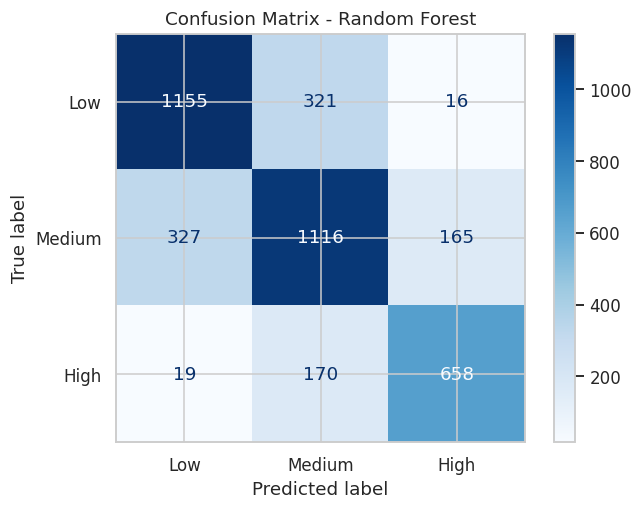

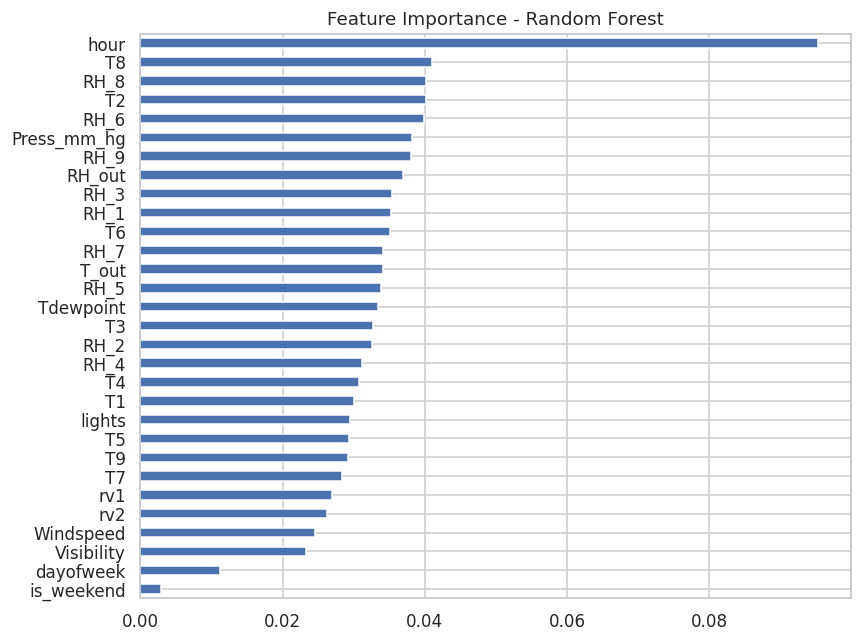


Top 10 features:
hour           0.095219
T8             0.041005
RH_8           0.040218
T2             0.040144
RH_6           0.039824
Press_mm_hg    0.038261
RH_9           0.038089
RH_out         0.036901
RH_3           0.035337
RH_1           0.035192
dtype: float64

Done. Files saved: model_comparison.csv, confusion_matrix.png, feature_importance.png


In [39]:
best_name = results_df.index[0]
best_model = best_models[best_name]
best_pred = best_model.predict(X_test_s)

print(f"\n=== Best model: {best_name} ===")
print(classification_report(y_test, best_pred))

cm = confusion_matrix(y_test, best_pred, labels=["Low", "Medium", "High"])
ConfusionMatrixDisplay(cm, display_labels=["Low", "Medium", "High"]).plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()

# Feature importance (only meaningful for the tree-based models)
if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=X.columns)
    importances = importances.sort_values(ascending=False)

    plt.figure(figsize=(8, 6))
    importances.plot(kind="barh")
    plt.gca().invert_yaxis()
    plt.title(f"Feature Importance - {best_name}")
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=120)
    plt.show()

    print("\nTop 10 features:")
    print(importances.head(10))


# The Random Forest performs consistently across the three classes, with
# F1-scores of 0.78 for High, 0.77 for Low, and 0.69 for Medium. Its
# macro F1-score of 0.75 indicates relatively balanced classification
# performance, although the Medium class remains somewhat more difficult
# to classify.